# AE 352 Group 24: Quadcopter Digital Twin

A 6-DOF digital twin of a Holybro X500 V2 quadcopter (4S 5200 mAh LiPo). The **only inputs** to the
model are the four motor torques (ER2). This notebook holds the whole simulation:

1. Physical parameters (from the bill of materials)
2. Rotation kinematics
3. Equations of motion
4. Reference trajectories
5. Flight controller
6. Simulator
7. Performance-goal missions and requirement checks
8. Plotting
9. Running PG1, PG2, PG3
10. Physics sanity tests

Run all cells top to bottom (*Run → Run All Cells*). Figures are saved to `figures/` and metrics to
`results/summary.json`. The three missions take about 2 minutes in total to simulate.

In [1]:
import json
import math
import unittest
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = Path.cwd()
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"

## 1. Physical parameters

Physical parameters of the digital twin.

All values are derived from the off-the-shelf bill of materials (Holybro X500 V2
kit, Tattu 4S 5200 mAh LiPo, Pixhawk 6C, PM02D power module, M8N GPS).
SI units throughout. Body frame is FLU (x forward, y left, z up); world frame
is ENU-like with z pointing up.

Values marked ASSUMED are not on a datasheet and should be checked against
test data (e.g. the Tyto Robotics propeller database) before the final report.

In [2]:
# --------------------------------------------------------------------------
# Component masses [kg] (from team bill of materials)
# --------------------------------------------------------------------------
COMPONENT_MASSES = {
    "frame": 0.610,
    "battery": 0.4365,
    "motors": 4 * 0.064,
    "escs": 4 * 0.021,
    "propellers": 4 * 0.0125,
    "flight_controller": 0.0593,
    "power_module": 0.020,
    "gps": 0.036,
}


def _inertia_estimate(arm: float) -> np.ndarray:
    """Estimate the body inertia tensor [kg m^2] from the component layout.

    Model:
      * motor + ESC + propeller: point masses at the end of each arm (X layout)
      * arms: 4 thin carbon rods from the hub to the motor (ASSUMED 60 g each,
        taken out of the 610 g frame mass)
      * landing gear: ASSUMED 110 g, lumped as two skids 0.2 m below the hub
      * central plates + avionics: solid box 0.144 x 0.144 x 0.03 m
      * battery: solid box 0.133 x 0.045 x 0.0335 m mounted 4 cm below the hub
    """
    a = arm / math.sqrt(2.0)
    m = COMPONENT_MASSES
    m_tip = (m["motors"] + m["escs"] + m["propellers"]) / 4.0
    m_arm = 0.060
    m_gear = 0.110
    m_hub = (m["frame"] - 4 * m_arm - m_gear) + m["flight_controller"] + m["power_module"] + m["gps"]

    I = np.zeros((3, 3))

    # Point masses at the arm tips
    for sx, sy in [(1, 1), (1, -1), (-1, 1), (-1, -1)]:
        r = np.array([sx * a, sy * a, 0.0])
        I += m_tip * (np.dot(r, r) * np.eye(3) - np.outer(r, r))

    # Arms: thin rods along the diagonals, length = arm
    rod_about_end = m_arm * arm**2 / 3.0
    # Each rod lies at 45 deg in the x-y plane -> half of its in-plane inertia
    # goes to Ixx and half to Iyy; full value goes to Izz.
    I += np.diag([2 * rod_about_end, 2 * rod_about_end, 4 * rod_about_end])

    # Hub box
    def box(mass, lx, ly, lz):
        return mass / 12.0 * np.diag([ly**2 + lz**2, lx**2 + lz**2, lx**2 + ly**2])

    I += box(m_hub, 0.144, 0.144, 0.03)

    # Battery box, offset below the hub (parallel axis for x and y)
    zb = -0.04
    I += box(m["battery"], 0.133, 0.045, 0.0335) + m["battery"] * np.diag([zb**2, zb**2, 0.0])

    # Landing gear: two skids at y = +-0.1 m, z = -0.2 m
    for sy in (1, -1):
        r = np.array([0.0, sy * 0.10, -0.20])
        I += (m_gear / 2) * (np.dot(r, r) * np.eye(3) - np.outer(r, r))

    return I


@dataclass
class DroneParams:
    # ---- Environment ----------------------------------------------------
    g: float = 9.81                     # gravitational acceleration [m/s^2]
    rho: float = 1.225                  # air density, sea level ISA [kg/m^3]

    # ---- Airframe -------------------------------------------------------
    mass: float = sum(COMPONENT_MASSES.values())   # total mass [kg]
    arm: float = 0.25                   # hub-to-motor distance [m] (500 mm wheelbase / 2)
    I: np.ndarray = field(default_factory=lambda: _inertia_estimate(0.25))
    CdA: float = 0.06                   # ASSUMED drag area Cd*A for translational drag [m^2]

    # ---- Propeller (10 in, ~4.5 in pitch, X500 V2 stock prop) ------------
    D: float = 0.254                    # propeller diameter [m]
    C_T: float = 0.11                   # ASSUMED static thrust coefficient (T = C_T rho n^2 D^4)
    C_P: float = 0.045                  # ASSUMED static power coefficient (P = C_P rho n^3 D^5)
    J_rotor: float = 7.5e-5             # rotor (prop + motor bell) inertia [kg m^2]

    # ---- Motor (Holybro 2216 KV920) ---------------------------------------
    KV: float = 920.0                   # speed constant [rpm/V]
    R_motor: float = 0.12               # ASSUMED winding resistance [ohm]
    I0: float = 0.8                     # no-load current [A] (datasheet @10 V)
    I_max: float = 17.0                 # peak current, 180 s rating [A]
    eta_esc: float = 0.95               # ASSUMED ESC efficiency [-]

    # ---- Battery (Tattu 4S1P 5200 mAh 35C) --------------------------------
    n_cells: int = 4
    capacity_Ah: float = 5.2
    R_batt: float = 0.020               # ASSUMED pack internal resistance [ohm]
    usable_fraction: float = 0.80       # do not discharge below 20 % SOC
    P_avionics: float = 5.0             # FC + GPS + power module draw [W]

    # ---- Geometry: PX4 "quad X" motor numbering, converted to FLU -------
    # Motor 1 front-right CCW, 2 rear-left CCW, 3 front-left CW, 4 rear-right CW.
    # spin = +1 means the rotor angular velocity points along +z_body (CCW seen from above).
    spin: np.ndarray = field(default_factory=lambda: np.array([1.0, 1.0, -1.0, -1.0]))

    def __post_init__(self):
        a = self.arm / math.sqrt(2.0)
        self.rotor_pos = np.array([
            [a, -a, 0.0],    # 1 front-right
            [-a, a, 0.0],    # 2 rear-left
            [a, a, 0.0],     # 3 front-left
            [-a, -a, 0.0],   # 4 rear-right
        ])
        self.I_inv = np.linalg.inv(self.I)

    # ---- Derived propeller constants (per rad/s) ----------------------------
    @property
    def k_T(self) -> float:
        """Thrust constant: T = k_T * omega^2, omega in rad/s."""
        return self.C_T * self.rho * self.D**4 / (2 * math.pi) ** 2

    @property
    def k_Q(self) -> float:
        """Aerodynamic torque constant: Q = k_Q * omega^2."""
        C_Q = self.C_P / (2 * math.pi)
        return C_Q * self.rho * self.D**5 / (2 * math.pi) ** 2

    # ---- Derived motor constants -----------------------------------------
    @property
    def Kv_rad(self) -> float:
        """Speed constant [rad/s per V]."""
        return self.KV * 2 * math.pi / 60.0

    @property
    def Kt(self) -> float:
        """Torque constant [N m / A] (= 1 / Kv in SI)."""
        return 1.0 / self.Kv_rad

    @property
    def tau_friction(self) -> float:
        """Bearing/eddy friction torque inferred from the no-load current."""
        return self.Kt * self.I0

    # ---- Battery -------------------------------------------------------------
    @property
    def capacity_C(self) -> float:
        return self.capacity_Ah * 3600.0

    def open_circuit_voltage(self, soc: float) -> float:
        """Simple linear LiPo model: 3.5 V/cell empty to 4.2 V/cell full."""
        soc = min(max(soc, 0.0), 1.0)
        return self.n_cells * (3.5 + 0.7 * soc)

    # ---- Convenience -------------------------------------------------------
    @property
    def weight(self) -> float:
        return self.mass * self.g

    @property
    def omega_hover(self) -> float:
        return math.sqrt(self.weight / (4 * self.k_T))

    @property
    def tau_motor_max(self) -> float:
        """Current-limited electromagnetic torque [N m]."""
        return self.Kt * self.I_max

    def omega_max(self) -> float:
        """Steady rotor speed at the current-limited torque."""
        return math.sqrt((self.tau_motor_max - self.tau_friction) / self.k_Q)

    @property
    def thrust_max(self) -> float:
        return self.k_T * self.omega_max() ** 2


DEFAULT = DroneParams()

In [3]:
p = DEFAULT
print(f"mass             {p.mass:.4f} kg")
print(f"inertia diag     {np.diag(p.I)} kg m^2")
print(f"k_T, k_Q         {p.k_T:.3e}, {p.k_Q:.3e}")
print(f"hover speed      {p.omega_hover * 60 / (2 * math.pi):.0f} rpm")
print(f"max speed        {p.omega_max() * 60 / (2 * math.pi):.0f} rpm")
print(f"thrust / weight  {4 * p.thrust_max / p.weight:.2f}")

mass             1.5518 kg
inertia diag     [0.02167705 0.02114683 0.03248913] kg m^2
k_T, k_Q         1.421e-05, 2.350e-07
hover speed      4942 rpm
max speed        8079 rpm
thrust / weight  2.67


## 2. Rotation kinematics

ZYX (yaw-pitch-roll) Euler angle kinematics.

R = Rz(psi) @ Ry(theta) @ Rx(phi) maps body-frame vectors to the world frame.

In [4]:
def rotation_matrix(phi: float, theta: float, psi: float) -> np.ndarray:
    cf, sf = math.cos(phi), math.sin(phi)
    ct, st = math.cos(theta), math.sin(theta)
    cp, sp = math.cos(psi), math.sin(psi)
    return np.array([
        [cp * ct, cp * st * sf - sp * cf, cp * st * cf + sp * sf],
        [sp * ct, sp * st * sf + cp * cf, sp * st * cf - cp * sf],
        [-st, ct * sf, ct * cf],
    ])


def euler_rate_matrix(phi: float, theta: float) -> np.ndarray:
    """W such that [phi_dot, theta_dot, psi_dot] = W @ [p, q, r]."""
    cf, sf = math.cos(phi), math.sin(phi)
    ct, tt = math.cos(theta), math.tan(theta)
    return np.array([
        [1.0, sf * tt, cf * tt],
        [0.0, cf, -sf],
        [0.0, sf / ct, cf / ct],
    ])


def euler_from_matrix(R: np.ndarray) -> np.ndarray:
    phi = math.atan2(R[2, 1], R[2, 2])
    theta = -math.asin(max(-1.0, min(1.0, R[2, 0])))
    psi = math.atan2(R[1, 0], R[0, 0])
    return np.array([phi, theta, psi])


def wrap_angle(a: float) -> float:
    return (a + math.pi) % (2 * math.pi) - math.pi

## 3. Equations of motion

Equations of motion of the quadcopter digital twin.

State vector x (17 entries):
    0:3    r      CoM position in world frame [m]
    3:6    v      CoM velocity in world frame [m/s]
    6:9    eta    ZYX Euler angles (phi, theta, psi) [rad]
    9:12   w      body angular velocity (p, q, r) [rad/s]
    12:16  Omega  rotor speeds (magnitudes) [rad/s]
    16     q_used battery charge drawn [C]

Input u (4 entries): electromagnetic motor torque on each rotor [N m].
This is the ONLY input to the model (ER2): thrust, attitude and position all
change only because motor torques change the rotor speeds.

Equations (see report Section 3):
    r_dot     = v
    m v_dot   = R(eta) [0, 0, sum T_i] - m g e_z - 1/2 rho CdA |v - v_w| (v - v_w)
    eta_dot   = W(eta) w
    I w_dot   = M_thrust + M_reaction - w x (I w) - w x h_rotors
    J_r Om_i' = tau_i - k_Q Om_i^2 - tau_f
    q_used'   = I_battery
with T_i = k_T Om_i^2, M_thrust = sum r_i x [0, 0, T_i],
M_reaction = -sum s_i tau_i e_z (motor reaction torque on the airframe),
h_rotors = J_r sum s_i Om_i e_z (rotor angular momentum, gyroscopic coupling).

In [5]:
N_STATE = 17
E_Z = np.array([0.0, 0.0, 1.0])


def clip_motor_torque(tau_cmd: np.ndarray, omega: np.ndarray, v_batt: float, p: DroneParams) -> np.ndarray:
    """Physical limits of the motor/ESC: current limit and back-EMF voltage limit.

    Positive torque requires V_batt > back-EMF; negative (active braking) torque
    is limited by the current rating.
    """
    i_volt = np.maximum(0.0, (v_batt - omega / p.Kv_rad) / p.R_motor)
    tau_hi = p.Kt * np.minimum(p.I_max, i_volt)
    tau_lo = -p.Kt * p.I_max
    return np.clip(tau_cmd, tau_lo, tau_hi)


def electrical(tau: np.ndarray, omega: np.ndarray, soc: float, p: DroneParams):
    """Battery current, terminal voltage and per-motor phase current.

    Motor: I = |tau| / Kt, V = Omega / Kv + I R  ->  P_motor = V I (no regen
    when braking). Battery: V_t = V_oc(SOC) - I_b R_b with
    I_b = (sum P_motor / eta_esc + P_avionics) / V_t, solved in closed form.
    """
    i_m = np.abs(tau) / p.Kt
    v_m = np.where(tau >= 0.0, omega / p.Kv_rad + i_m * p.R_motor, i_m * p.R_motor)
    p_elec = float(np.sum(v_m * i_m)) / p.eta_esc + p.P_avionics
    v_oc = p.open_circuit_voltage(soc)
    # V_t * I_b = P, V_t = v_oc - I_b R  ->  R I_b^2 - v_oc I_b + P = 0
    disc = v_oc**2 - 4 * p.R_batt * p_elec
    i_b = (v_oc - math.sqrt(max(disc, 0.0))) / (2 * p.R_batt)
    v_t = v_oc - i_b * p.R_batt
    return i_b, v_t, i_m, p_elec


def state_of_charge(x: np.ndarray, p: DroneParams) -> float:
    return 1.0 - x[16] / p.capacity_C


def derivatives(x: np.ndarray, tau: np.ndarray, p: DroneParams, wind: np.ndarray | None = None) -> np.ndarray:
    v = x[3:6]
    phi, theta, psi = x[6], x[7], x[8]
    w = x[9:12]
    omega = np.maximum(x[12:16], 0.0)

    R = rotation_matrix(phi, theta, psi)
    thrusts = p.k_T * omega**2

    # Translational dynamics (Newton)
    v_rel = v if wind is None else v - wind
    drag = -0.5 * p.rho * p.CdA * np.linalg.norm(v_rel) * v_rel
    acc = (R @ (E_Z * thrusts.sum()) + drag) / p.mass - p.g * E_Z

    # Rotational dynamics (Euler)
    m_thrust = np.array([
        np.dot(p.rotor_pos[:, 1], thrusts),
        -np.dot(p.rotor_pos[:, 0], thrusts),
        0.0,
    ])
    m_reaction = np.array([0.0, 0.0, -np.dot(p.spin, tau)])
    h_rotor = np.array([0.0, 0.0, p.J_rotor * np.dot(p.spin, omega)])
    moments = m_thrust + m_reaction - np.cross(w, p.I @ w) - np.cross(w, h_rotor)
    w_dot = p.I_inv @ moments

    # Rotor dynamics (friction opposes rotation only while spinning)
    friction = p.tau_friction * np.tanh(omega / 5.0)
    omega_dot = (tau - p.k_Q * omega**2 - friction) / p.J_rotor
    omega_dot = np.where((x[12:16] <= 0.0) & (omega_dot < 0.0), 0.0, omega_dot)

    i_b, *_ = electrical(tau, omega, state_of_charge(x, p), p)

    dx = np.empty(N_STATE)
    dx[0:3] = v
    dx[3:6] = acc
    dx[6:9] = euler_rate_matrix(phi, theta) @ w
    dx[9:12] = w_dot
    dx[12:16] = omega_dot
    dx[16] = i_b
    return dx


def rk4_step(x: np.ndarray, tau: np.ndarray, dt: float, p: DroneParams, wind=None) -> np.ndarray:
    k1 = derivatives(x, tau, p, wind)
    k2 = derivatives(x + 0.5 * dt * k1, tau, p, wind)
    k3 = derivatives(x + 0.5 * dt * k2, tau, p, wind)
    k4 = derivatives(x + dt * k3, tau, p, wind)
    return x + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)


def apply_ground_contact(x: np.ndarray) -> tuple[np.ndarray, bool]:
    """Unilateral ground constraint at z = 0 (landing gear on flat ground).

    If the CoM reaches the ground, it cannot penetrate it; the landing gear
    holds the airframe level and friction stops sliding/spinning.
    """
    if x[2] > 0.0:
        return x, False
    x = x.copy()
    x[2] = 0.0
    x[3:6] = 0.0 if x[5] <= 0.0 else np.array([0.0, 0.0, x[5]])
    x[6:8] = 0.0
    x[9:12] = 0.0
    return x, True

## 4. Reference trajectories

Reference trajectories built from smooth segments.

Each segment returns a Reference with position, velocity and acceleration
(world frame), yaw angle and yaw rate. Segments are chained in a Mission,
which also records named phases so requirements can be checked afterwards.

In [6]:
@dataclass
class Reference:
    pos: np.ndarray
    vel: np.ndarray
    acc: np.ndarray
    yaw: float = 0.0
    yaw_rate: float = 0.0
    armed: bool = True


def _min_jerk(tau: float):
    """Quintic min-jerk blend s(tau) on [0, 1] and its first two derivatives."""
    tau = min(max(tau, 0.0), 1.0)
    s = 10 * tau**3 - 15 * tau**4 + 6 * tau**5
    ds = 30 * tau**2 - 60 * tau**3 + 30 * tau**4
    dds = 60 * tau - 180 * tau**2 + 120 * tau**3
    return s, ds, dds


class Segment:
    duration: float
    name: str

    def __call__(self, t: float) -> Reference:  # pragma: no cover - interface
        raise NotImplementedError

    @property
    def end(self) -> Reference:
        return self(self.duration)


class Hold(Segment):
    """Hold a fixed position and yaw (hover, or sit on the ground disarmed)."""

    def __init__(self, pos, yaw: float, duration: float, name: str = "hold", armed: bool = True):
        self.pos = np.asarray(pos, float)
        self.yaw = yaw
        self.duration = duration
        self.name = name
        self.armed = armed

    def __call__(self, t):
        z = np.zeros(3)
        return Reference(self.pos.copy(), z, z.copy(), self.yaw, 0.0, self.armed)


class MinJerkLine(Segment):
    """Rest-to-rest straight line with a quintic (minimum-jerk) time law."""

    def __init__(self, p0, p1, duration: float, yaw: float, name: str = "line"):
        self.p0 = np.asarray(p0, float)
        self.p1 = np.asarray(p1, float)
        self.duration = duration
        self.yaw = yaw
        self.name = name

    def __call__(self, t):
        T = self.duration
        s, ds, dds = _min_jerk(t / T)
        d = self.p1 - self.p0
        return Reference(self.p0 + s * d, ds / T * d, dds / T**2 * d, self.yaw, 0.0)


class YawTurn(Segment):
    """Rotate in place from yaw0 to yaw1 with a min-jerk yaw profile."""

    def __init__(self, pos, yaw0: float, yaw1: float, duration: float, name: str = "yaw"):
        self.pos = np.asarray(pos, float)
        self.yaw0, self.yaw1 = yaw0, yaw1
        self.duration = duration
        self.name = name

    def __call__(self, t):
        T = self.duration
        s, ds, _ = _min_jerk(t / T)
        dy = self.yaw1 - self.yaw0
        z = np.zeros(3)
        return Reference(self.pos.copy(), z, z.copy(), self.yaw0 + s * dy, ds / T * dy)


class ConstantSpeedLine(Segment):
    """Straight line at a constant cruise speed with smooth accel/decel ramps.

    Speed profile: smoothstep ramp up over t_ramp, cruise, smoothstep ramp
    down over t_ramp. The peak speed never exceeds `speed`, which is how the
    1 cm/s landing-speed limit is enforced.
    """

    def __init__(self, p0, p1, speed: float, yaw: float, t_ramp: float = 2.0, name: str = "cruise"):
        self.p0 = np.asarray(p0, float)
        self.p1 = np.asarray(p1, float)
        L = float(np.linalg.norm(self.p1 - self.p0))
        self.u = (self.p1 - self.p0) / L
        self.speed = speed
        self.t_ramp = t_ramp
        # distance covered in one smoothstep ramp = speed * t_ramp / 2
        self.t_cruise = (L - speed * t_ramp) / speed
        if self.t_cruise < 0:
            raise ValueError("segment too short for the requested ramp time")
        self.duration = 2 * t_ramp + self.t_cruise
        self.yaw = yaw
        self.name = name

    def _profile(self, t):
        V, Tr, Tc = self.speed, self.t_ramp, self.t_cruise
        if t <= 0:
            return 0.0, 0.0, 0.0
        if t < Tr:
            x = t / Tr
            return V * Tr * (x**3 - 0.5 * x**4), V * (3 * x**2 - 2 * x**3), V / Tr * (6 * x - 6 * x**2)
        d_ramp = 0.5 * V * Tr
        if t < Tr + Tc:
            return d_ramp + V * (t - Tr), V, 0.0
        tt = min(t - Tr - Tc, Tr)
        x = tt / Tr
        s = V * Tr * (x - x**3 + 0.5 * x**4)
        return d_ramp + V * Tc + s, V * (1 - 3 * x**2 + 2 * x**3), -V / Tr * (6 * x - 6 * x**2)

    def __call__(self, t):
        s, ds, dds = self._profile(t)
        return Reference(self.p0 + s * self.u, ds * self.u, dds * self.u, self.yaw, 0.0)


class Circle(Segment):
    """Horizontal circle at constant tangential speed with smooth spin-up/down.

    Starts and ends at center + [radius, 0, 0] (angle 0). The angular rate
    ramps from 0 to speed/radius over t_ramp (smoothstep), stays constant, and
    ramps back to zero, so that the total swept angle is exactly n_laps * 2 pi.
    (The two ramps together sweep speed/radius * t_ramp radians.)
    """

    def __init__(self, center, radius: float, speed: float, n_laps: float, yaw: float = 0.0,
                 t_ramp: float = 4.0, name: str = "circle"):
        self.c = np.asarray(center, float)
        self.R = radius
        self.w0 = speed / radius
        self.t_ramp = t_ramp
        self.t_const = (n_laps * 2 * math.pi - self.w0 * t_ramp) / self.w0
        if self.t_const < 0:
            raise ValueError("ramp too long for the requested number of laps")
        self.duration = 2 * t_ramp + self.t_const
        self.yaw = yaw
        self.name = name

    def _phase(self, t):
        w0, Tr, Tc = self.w0, self.t_ramp, self.t_const
        if t < Tr:
            x = t / Tr
            return w0 * Tr * (x**3 - 0.5 * x**4), w0 * (3 * x**2 - 2 * x**3), w0 / Tr * (6 * x - 6 * x**2)
        a_ramp = 0.5 * w0 * Tr
        if t < Tr + Tc:
            return a_ramp + w0 * (t - Tr), w0, 0.0
        x = min(t - Tr - Tc, Tr) / Tr
        return (a_ramp + w0 * Tc + w0 * Tr * (x - x**3 + 0.5 * x**4),
                w0 * (1 - 3 * x**2 + 2 * x**3), -w0 / Tr * (6 * x - 6 * x**2))

    def __call__(self, t):
        a, da, dda = self._phase(t)
        R = self.R
        ca, sa = math.cos(a), math.sin(a)
        pos = self.c + np.array([R * ca, R * sa, 0.0])
        vel = np.array([-R * sa * da, R * ca * da, 0.0])
        acc = np.array([-R * ca * da**2 - R * sa * dda, -R * sa * da**2 + R * ca * dda, 0.0])
        return Reference(pos, vel, acc, self.yaw, 0.0)


class Mission:
    """A sequence of segments evaluated as a single function of time."""

    def __init__(self, name: str, segments: list[Segment]):
        self.name = name
        self.segments = segments
        self.starts = np.cumsum([0.0] + [s.duration for s in segments[:-1]])
        self.duration = float(sum(s.duration for s in segments))

    def __call__(self, t: float) -> Reference:
        i = int(np.searchsorted(self.starts, t, side="right") - 1)
        i = min(max(i, 0), len(self.segments) - 1)
        return self.segments[i](min(t - self.starts[i], self.segments[i].duration))

    def phase_window(self, name: str) -> tuple[float, float]:
        for s, t0 in zip(self.segments, self.starts):
            if s.name == name:
                return float(t0), float(t0 + s.duration)
        raise KeyError(name)

## 5. Flight controller

Flight controller: cascaded position -> attitude -> rotor speed -> motor torque.

The controller only ever outputs the four motor torques (ER2). Internally:
  1. Position loop (PID + trajectory feedforward) gives a desired force vector.
  2. The force direction plus the reference yaw define the desired attitude;
     its projection on the body z-axis gives the collective thrust.
  3. Attitude loop (PD with feedforward yaw rate) gives desired body moments.
  4. Mixer inverts the rotor allocation matrix to get per-rotor thrusts, then
     rotor speeds Omega_des = sqrt(T_i / k_T).
  5. Speed loop (the ESC) computes motor torque: aero torque feedforward plus
     proportional speed correction.

In [7]:
@dataclass
class Gains:
    kp_pos: np.ndarray = field(default_factory=lambda: np.array([4.0, 4.0, 6.0]))
    kd_pos: np.ndarray = field(default_factory=lambda: np.array([3.6, 3.6, 4.5]))
    ki_pos: np.ndarray = field(default_factory=lambda: np.array([0.4, 0.4, 1.0]))
    i_limit: float = 2.0                     # integrator clamp [m s]
    kp_att: np.ndarray = field(default_factory=lambda: np.array([150.0, 150.0, 40.0]))
    kd_att: np.ndarray = field(default_factory=lambda: np.array([20.0, 20.0, 12.0]))
    k_speed: float = 60.0                    # ESC speed-loop bandwidth [1/s]
    max_tilt: float = math.radians(35.0)


class Controller:
    def __init__(self, p: DroneParams, gains: Gains | None = None):
        self.p = p
        self.g = gains or Gains()
        self.i_err = np.zeros(3)

        # Allocation: [T, Mx, My, Mz] = A @ [T1..T4]; steady yaw moment = -s_i (k_Q/k_T) T_i
        c = p.k_Q / p.k_T
        self.A = np.vstack([
            np.ones(4),
            p.rotor_pos[:, 1],
            -p.rotor_pos[:, 0],
            -c * p.spin,
        ])
        self.A_inv = np.linalg.inv(self.A)
        self.T_rotor_max = p.thrust_max
        self.last = {}

    def reset(self):
        self.i_err[:] = 0.0

    def __call__(self, x: np.ndarray, ref: Reference, dt: float, v_batt: float, on_ground: bool) -> np.ndarray:
        p, g = self.p, self.g
        omega = x[12:16]

        if not ref.armed:
            self.reset()
            omega_des = np.zeros(4)
            self.last = {"omega_des": omega_des, "euler_des": np.array([0.0, 0.0, ref.yaw])}
            return clip_motor_torque(-g.k_speed * p.J_rotor * omega, omega, v_batt, p)

        pos, vel = x[0:3], x[3:6]
        phi, theta, psi = x[6:9]
        w = x[9:12]

        # ---- 1. position loop ----------------------------------------------
        e_p = ref.pos - pos
        e_v = ref.vel - vel
        if not on_ground:
            self.i_err = np.clip(self.i_err + e_p * dt, -g.i_limit, g.i_limit)
        a_cmd = ref.acc + g.kp_pos * e_p + g.kd_pos * e_v + g.ki_pos * self.i_err
        f_des = p.mass * (a_cmd + np.array([0.0, 0.0, p.g]))
        f_des[2] = max(f_des[2], 0.1 * p.weight)

        # limit tilt: shrink the horizontal part if needed
        horiz = math.hypot(f_des[0], f_des[1])
        max_h = f_des[2] * math.tan(g.max_tilt)
        if horiz > max_h:
            f_des[0:2] *= max_h / horiz

        # ---- 2. desired attitude ---------------------------------------------
        zb = f_des / np.linalg.norm(f_des)
        xc = np.array([math.cos(ref.yaw), math.sin(ref.yaw), 0.0])
        yb = np.cross(zb, xc)
        yb /= np.linalg.norm(yb)
        xb = np.cross(yb, zb)
        R_des = np.column_stack([xb, yb, zb])
        euler_des = euler_from_matrix(R_des)

        cf, sf = math.cos(phi), math.sin(phi)
        ct, st = math.cos(theta), math.sin(theta)
        zb_now = np.array([
            math.cos(psi) * st * cf + math.sin(psi) * sf,
            math.sin(psi) * st * cf - math.cos(psi) * sf,
            ct * cf,
        ])
        T_cmd = max(float(f_des @ zb_now), 0.0)

        # ---- 3. attitude loop ------------------------------------------------
        e_att = np.array([
            euler_des[0] - phi,
            euler_des[1] - theta,
            wrap_angle(euler_des[2] - psi),
        ])
        w_des = np.array([0.0, 0.0, ref.yaw_rate])
        alpha = g.kp_att * e_att + g.kd_att * (w_des - w)
        M_cmd = p.I @ alpha + np.cross(w, p.I @ w)

        # ---- 4. mixer -> rotor speeds ----------------------------------------
        T_rotor = self.A_inv @ np.array([T_cmd, *M_cmd])
        T_rotor = np.clip(T_rotor, 0.0, self.T_rotor_max)
        omega_des = np.sqrt(T_rotor / p.k_T)

        # ---- 5. ESC speed loop -> motor torque -------------------------------
        tau = (p.k_Q * omega_des**2 + p.tau_friction
               + g.k_speed * p.J_rotor * (omega_des - omega))
        tau = clip_motor_torque(tau, omega, v_batt, p)

        self.last = {"omega_des": omega_des, "euler_des": euler_des, "T_cmd": T_cmd}
        return tau

## 6. Simulator

Fixed-step closed-loop simulation of the digital twin.

In [8]:
@dataclass
class SimResult:
    mission: Mission
    params: DroneParams
    t: np.ndarray
    x: np.ndarray            # (N, 17) states
    tau: np.ndarray          # (N, 4) motor torques [N m]
    omega_des: np.ndarray    # (N, 4) commanded rotor speeds [rad/s]
    ref_pos: np.ndarray      # (N, 3)
    ref_vel: np.ndarray      # (N, 3)
    ref_yaw: np.ndarray      # (N,)
    euler_des: np.ndarray    # (N, 3)
    i_batt: np.ndarray       # (N,) battery current [A]
    v_batt: np.ndarray       # (N,) battery terminal voltage [V]
    i_motor: np.ndarray      # (N, 4) motor phase current [A]
    p_elec: np.ndarray       # (N,) electrical power drawn from battery [W]
    on_ground: np.ndarray    # (N,) bool

    @property
    def pos(self):
        return self.x[:, 0:3]

    @property
    def vel(self):
        return self.x[:, 3:6]

    @property
    def euler(self):
        return self.x[:, 6:9]

    @property
    def rates(self):
        return self.x[:, 9:12]

    @property
    def omega(self):
        return self.x[:, 12:16]

    @property
    def soc(self):
        return 1.0 - self.x[:, 16] / self.params.capacity_C

    def window(self, t0: float, t1: float) -> np.ndarray:
        return (self.t >= t0) & (self.t <= t1)


def initial_state(pos=(0.0, 0.0, 0.0), yaw: float = 0.0, omega: float = 0.0) -> np.ndarray:
    x = np.zeros(N_STATE)
    x[0:3] = pos
    x[8] = yaw
    x[12:16] = omega
    return x


def simulate(mission: Mission, params: DroneParams | None = None, x0: np.ndarray | None = None,
             dt: float = 0.002, gains: Gains | None = None,
             wind: Callable[[float], np.ndarray] | None = None) -> SimResult:
    """Run the closed-loop simulation over the whole mission.

    The controller runs at 1/dt (500 Hz by default) and holds the motor
    torques constant over each RK4 integration step (zero-order hold).
    """
    p = params or DroneParams()
    ctrl = Controller(p, gains)
    if x0 is None:
        r0 = mission(0.0)
        x0 = initial_state(r0.pos, r0.yaw)
    n = int(round(mission.duration / dt)) + 1

    t = np.arange(n) * dt
    X = np.zeros((n, N_STATE))
    TAU = np.zeros((n, 4))
    OMD = np.zeros((n, 4))
    RP, RV = np.zeros((n, 3)), np.zeros((n, 3))
    RY = np.zeros(n)
    ED = np.zeros((n, 3))
    IB, VB, PE = np.zeros(n), np.zeros(n), np.zeros(n)
    IM = np.zeros((n, 4))
    GND = np.zeros(n, bool)

    x = x0.astype(float).copy()
    x, on_ground = apply_ground_contact(x)
    v_batt = p.open_circuit_voltage(state_of_charge(x, p))

    for k in range(n):
        tk = t[k]
        ref = mission(tk)
        tau = ctrl(x, ref, dt, v_batt, on_ground)
        i_b, v_batt, i_m, p_el = electrical(tau, x[12:16], state_of_charge(x, p), p)

        X[k], TAU[k], OMD[k] = x, tau, ctrl.last["omega_des"]
        RP[k], RV[k], RY[k] = ref.pos, ref.vel, ref.yaw
        ED[k] = ctrl.last["euler_des"]
        IB[k], VB[k], IM[k], PE[k], GND[k] = i_b, v_batt, i_m, p_el, on_ground

        if k < n - 1:
            w = wind(tk) if wind is not None else None
            x = rk4_step(x, tau, dt, p, w)
            x[12:16] = np.maximum(x[12:16], 0.0)
            x, on_ground = apply_ground_contact(x)

    return SimResult(mission, p, t, X, TAU, OMD, RP, RV, RY, ED, IB, VB, IM, PE, GND)

## 7. Performance-goal missions and requirement checks

The three performance goals from the project statement, plus requirement checks.

In [9]:
ALT = 1.0
LAND_SPEED = 0.008      # [m/s] commanded descent speed, below the 1 cm/s limit
GROUND_OVERSHOOT = 0.02 # descend slightly "into" the ground so touchdown happens at cruise speed


def _takeoff(p0, yaw=0.0):
    p0 = np.asarray(p0, float)
    top = p0 + [0, 0, ALT]
    return [
        Hold(p0, yaw, 1.0, "spinup"),
        MinJerkLine(p0, top, 4.0, yaw, "climb"),
        Hold(top, yaw, 3.0, "settle"),
    ], top


def _landing(p_top, yaw=0.0, speed=LAND_SPEED):
    p_top = np.asarray(p_top, float)
    p_gnd = p_top.copy()
    p_gnd[2] = -GROUND_OVERSHOOT
    return [
        ConstantSpeedLine(p_top, p_gnd, speed, yaw, t_ramp=2.0, name="land"),
        Hold(p_gnd * [1, 1, 0], yaw, 2.0, "disarm", armed=False),
    ]


def pg1_hover(duration: float = 120.0) -> Mission:
    """PG1: hover 1 m above ground for 2 minutes."""
    segs, top = _takeoff([0, 0, 0])
    segs += [Hold(top, 0.0, duration, "hover"), Hold(top, 0.0, 1.0, "end")]
    return Mission("PG1 hover", segs)


def pg2_circle(radius: float = 2.0, speed: float = 0.5, n_laps: float = 3.0) -> Mission:
    """PG2: circle of radius 2 m at 1 m altitude and 0.5 m/s for >= 1 min."""
    start = [radius, 0, 0]
    segs, top = _takeoff(start)
    segs += [
        Circle([0, 0, ALT], radius, speed, n_laps, 0.0, t_ramp=4.0, name="circle"),
        Hold(top, 0.0, 3.0, "hover"),
    ]
    segs += _landing(top, speed=0.10)
    return Mission("PG2 circle", segs)


def pg3_waypoints() -> Mission:
    """PG3: take off, 5 m line at 1 m/s avg, hover, yaw 90 deg left, 5 m line, hover, land <= 1 cm/s."""
    segs, top = _takeoff([0, 0, 0])
    p1 = top + [5.0, 0, 0]
    p2 = p1 + [0, 5.0, 0]
    yaw2 = math.pi / 2
    segs += [
        MinJerkLine(top, p1, 5.0, 0.0, "leg1"),
        Hold(p1, 0.0, 3.0, "stop1"),
        YawTurn(p1, 0.0, yaw2, 4.0, "yaw"),
        Hold(p1, yaw2, 2.0, "settle2"),
        MinJerkLine(p1, p2, 5.0, yaw2, "leg2"),
        Hold(p2, yaw2, 3.0, "stop2"),
    ]
    segs += _landing(p2, yaw2)
    return Mission("PG3 waypoints", segs)


# --------------------------------------------------------------------------
# Requirement checks
# --------------------------------------------------------------------------

def _common(res: SimResult) -> dict:
    p = res.params
    airborne = ~res.on_ground
    return {
        "mass_kg": p.mass,
        "thrust_to_weight": 4 * p.thrust_max / p.weight,
        "hover_rpm": p.omega_hover * 60 / (2 * math.pi),
        "max_rpm": float(res.omega.max() * 60 / (2 * math.pi)),
        "max_motor_current_A": float(res.i_motor.max()),
        "motor_current_limit_A": p.I_max,
        "max_battery_current_A": float(res.i_batt.max()),
        "energy_used_Wh": float(np.trapezoid(res.p_elec, res.t) / 3600.0),
        "soc_end": float(res.soc[-1]),
        "soc_reserve_ok": bool(res.soc[-1] > 1 - p.usable_fraction),
        "min_voltage_V": float(res.v_batt.min()),
        "max_tilt_deg": float(np.degrees(np.abs(res.euler[airborne, :2]).max())) if airborne.any() else 0.0,
    }


def check_pg1(res: SimResult) -> dict:
    t0, t1 = res.mission.phase_window("hover")
    m = res.window(t0, t1)
    err = res.pos[m] - res.ref_pos[m]
    alt = res.pos[m, 2]
    out = _common(res)
    out.update({
        "hover_duration_s": t1 - t0,
        "altitude_mean_m": float(alt.mean()),
        "altitude_max_dev_m": float(np.abs(alt - ALT).max()),
        "pos_error_rms_m": float(np.sqrt((err**2).sum(1).mean())),
        "pos_error_max_m": float(np.linalg.norm(err, axis=1).max()),
    })
    out["pass"] = out["hover_duration_s"] >= 120 and out["altitude_max_dev_m"] < 0.05 and out["soc_reserve_ok"]
    return out


def check_pg2(res: SimResult) -> dict:
    seg = next(s for s in res.mission.segments if s.name == "circle")
    t0, _ = res.mission.phase_window("circle")
    t0, t1 = t0 + seg.t_ramp, t0 + seg.t_ramp + seg.t_const   # constant-speed portion
    m = res.window(t0, t1)
    r = np.linalg.norm(res.pos[m, :2], axis=1)
    spd = np.linalg.norm(res.vel[m, :2], axis=1)
    alt = res.pos[m, 2]
    out = _common(res)
    out.update({
        "circle_duration_s": t1 - t0,
        "radius_mean_m": float(r.mean()),
        "radius_max_dev_m": float(np.abs(r - 2.0).max()),
        "speed_mean_mps": float(spd.mean()),
        "speed_min_mps": float(spd.min()),
        "speed_max_mps": float(spd.max()),
        "altitude_max_dev_m": float(np.abs(alt - ALT).max()),
    })
    out["pass"] = (out["circle_duration_s"] >= 60 and out["radius_max_dev_m"] < 0.05
                   and abs(out["speed_mean_mps"] - 0.5) < 0.01 and out["altitude_max_dev_m"] < 0.05
                   and out["soc_reserve_ok"])
    return out


def check_pg3(res: SimResult) -> dict:
    out = _common(res)
    for leg, stop in (("leg1", "stop1"), ("leg2", "stop2")):
        # distance: settled hover point before the leg -> settled hover point after it
        t0, _ = res.mission.phase_window(leg)
        _, t_stop = res.mission.phase_window(stop)
        i0, i1 = np.searchsorted(res.t, [t0, t_stop])
        p_start, p_end = res.pos[i0, :2], res.pos[i1, :2]
        d = float(np.linalg.norm(p_end - p_start))
        # time: from leaving the start point to arriving within 1 cm of the end point
        travelled = np.linalg.norm(res.pos[i0:i1 + 1, :2] - p_start, axis=1)
        remaining = np.linalg.norm(res.pos[i0:i1 + 1, :2] - p_end, axis=1)
        k_dep = np.argmax(travelled > 0.01)
        k_arr = np.argmax(remaining < 0.01)
        t_move = res.t[i0 + k_arr] - res.t[i0 + k_dep]
        t0, t1 = res.mission.phase_window(leg)
        out[f"{leg}_distance_m"] = d
        out[f"{leg}_avg_speed_mps"] = d / (t1 - t0)          # rest-to-rest over the commanded leg time
        out[f"{leg}_travel_time_1cm_s"] = float(t_move)    # time outside 1 cm of both end points
        out[f"{leg}_max_alt_dev_m"] = float(np.abs(res.pos[i0:i1 + 1, 2] - ALT).max())

    t0, t1 = res.mission.phase_window("yaw")
    i0, i1 = np.searchsorted(res.t, [t0, t1 + 2.0])
    out["yaw_change_deg"] = float(np.degrees(res.euler[i1, 2] - res.euler[i0, 2]))

    t0, t1 = res.mission.phase_window("land")
    m = res.window(t0, t1)
    out["landing_max_descent_speed_mps"] = float(np.maximum(-res.vel[m, 2], 0).max())
    touch = np.argmax(res.on_ground & (res.t > t0))
    out["touchdown_time_s"] = float(res.t[touch])
    out["touchdown_speed_mps"] = float(-res.vel[touch - 1, 2])
    out["landing_horizontal_drift_m"] = float(np.linalg.norm(res.pos[m, :2] - res.pos[m][0, :2], axis=1).max())

    out["pass"] = (abs(out["leg1_distance_m"] - 5) < 0.05 and abs(out["leg2_distance_m"] - 5) < 0.05
                   and abs(out["leg1_avg_speed_mps"] - 1) < 0.02 and abs(out["leg2_avg_speed_mps"] - 1) < 0.02
                   and abs(out["yaw_change_deg"] - 90) < 1.0
                   and out["landing_max_descent_speed_mps"] <= 0.010 and out["soc_reserve_ok"])
    return out


MISSIONS = {
    "pg1": (pg1_hover, check_pg1),
    "pg2": (pg2_circle, check_pg2),
    "pg3": (pg3_waypoints, check_pg3),
}

## 8. Plotting

Figures for the report (RR4): every degree of freedom vs time, actuators, battery, path.

In [10]:
RPM = 60 / (2 * math.pi)
COLORS = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]

plt.rcParams.update({
    "font.size": 9,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
})


def _phase_shading(ax, res: SimResult):
    for i, (seg, t0) in enumerate(zip(res.mission.segments, res.mission.starts)):
        if i % 2:
            ax.axvspan(t0, t0 + seg.duration, color="0.92", zorder=0, lw=0)


def plot_states(res: SimResult, path: Path):
    t = res.t
    fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)

    ax = axes[0, 0]
    for i, lab in enumerate("xyz"):
        ax.plot(t, res.pos[:, i], color=COLORS[i], label=f"${lab}$")
        ax.plot(t, res.ref_pos[:, i], color=COLORS[i], ls="--", lw=0.8)
    ax.set_ylabel("CoM position [m]")
    ax.set_title("Position (dashed: reference)")
    ax.legend(ncol=3)

    ax = axes[0, 1]
    for i, lab in enumerate("xyz"):
        ax.plot(t, res.vel[:, i], color=COLORS[i], label=f"$\\dot {lab}$")
    ax.set_ylabel("CoM velocity [m/s]")
    ax.set_title("Velocity")
    ax.legend(ncol=3)

    ax = axes[1, 0]
    for i, lab in enumerate([r"\phi", r"\theta", r"\psi"]):
        ax.plot(t, np.degrees(res.euler[:, i]), color=COLORS[i], label=f"${lab}$")
        ax.plot(t, np.degrees(res.euler_des[:, i]), color=COLORS[i], ls="--", lw=0.8)
    ax.set_ylabel("Euler angles [deg]")
    ax.set_title("Attitude (dashed: commanded)")
    ax.legend(ncol=3)

    ax = axes[1, 1]
    for i, lab in enumerate("pqr"):
        ax.plot(t, np.degrees(res.rates[:, i]), color=COLORS[i], label=f"${lab}$")
    ax.set_ylabel("Body rates [deg/s]")
    ax.set_title("Angular velocity")
    ax.legend(ncol=3)

    ax = axes[2, 0]
    for i in range(4):
        ax.plot(t, res.omega[:, i] * RPM, color=COLORS[i], lw=0.9, label=f"rotor {i + 1}")
    ax.set_ylabel("Rotor speed [rpm]")
    ax.set_xlabel("Time [s]")
    ax.set_title("Rotor speeds")
    ax.legend(ncol=2)

    ax = axes[2, 1]
    for i in range(4):
        ax.plot(t, res.tau[:, i] * 1e3, color=COLORS[i], lw=0.9, label=f"motor {i + 1}")
    ax.set_ylabel("Motor torque [mN m]")
    ax.set_xlabel("Time [s]")
    ax.set_title("Control input: motor torques")
    ax.legend(ncol=2)

    for ax in axes.flat:
        _phase_shading(ax, res)
    fig.suptitle(res.mission.name)
    fig.tight_layout()
    fig.savefig(path.with_suffix(".pdf"))
    fig.savefig(path.with_suffix(".png"))
    plt.show()


def plot_power(res: SimResult, path: Path):
    t = res.t
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
    axes[0].plot(t, res.p_elec, color=COLORS[0])
    axes[0].set_ylabel("Electrical power [W]")
    axes[1].plot(t, res.i_batt, color=COLORS[1], label="battery")
    axes[1].plot(t, res.i_motor.max(1), color=COLORS[3], lw=0.8, label="max motor")
    axes[1].axhline(res.params.I_max, color="k", ls=":", lw=0.8, label="motor limit")
    axes[1].set_ylabel("Current [A]")
    axes[1].legend()
    axes[2].plot(t, 100 * res.soc, color=COLORS[2])
    axes[2].axhline(100 * (1 - res.params.usable_fraction), color="k", ls=":", lw=0.8)
    axes[2].set_ylabel("State of charge [%]")
    for ax in axes:
        ax.set_xlabel("Time [s]")
        _phase_shading(ax, res)
    fig.suptitle(f"{res.mission.name}: power and battery")
    fig.tight_layout()
    fig.savefig(path.with_suffix(".pdf"))
    fig.savefig(path.with_suffix(".png"))
    plt.show()


def plot_path(res: SimResult, path: Path):
    fig = plt.figure(figsize=(10, 4))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot(*res.ref_pos.T, "k--", lw=0.8, label="reference")
    ax.plot(*res.pos.T, color=COLORS[0], label="simulated")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.legend()

    ax = fig.add_subplot(1, 2, 2)
    ax.plot(res.ref_pos[:, 0], res.ref_pos[:, 1], "k--", lw=0.8, label="reference")
    ax.plot(res.pos[:, 0], res.pos[:, 1], color=COLORS[0], label="simulated")
    # heading arrows
    idx = np.linspace(0, len(res.t) - 1, 25).astype(int)
    psi = res.euler[idx, 2]
    ax.quiver(res.pos[idx, 0], res.pos[idx, 1], np.cos(psi), np.sin(psi),
              color=COLORS[1], scale=25, width=0.004, label="heading")
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title("Top view")
    ax.legend()
    fig.suptitle(f"{res.mission.name}: flight path")
    fig.tight_layout()
    fig.savefig(path.with_suffix(".pdf"))
    fig.savefig(path.with_suffix(".png"))
    plt.show()


def plot_all(res: SimResult, out_dir: Path, tag: str):
    out_dir.mkdir(parents=True, exist_ok=True)
    plot_states(res, out_dir / f"{tag}_states")
    plot_power(res, out_dir / f"{tag}_power")
    plot_path(res, out_dir / f"{tag}_path")

## 9. Run the performance goals

Each cell simulates one mission, checks it against the requirements, prints the metrics, and plots
every degree of freedom vs time, the actuators, the battery, and the flight path (RR4).

In [11]:
results = {}


def run_mission(tag: str):
    build, check = MISSIONS[tag]
    res = simulate(build())
    metrics = check(res)
    results[tag] = metrics
    print(f"=== {tag.upper()}  {'PASS' if metrics['pass'] else 'FAIL'} ===")
    for k, v in metrics.items():
        if k != "pass":
            print(f"  {k:32s} {v:.4g}" if isinstance(v, float) else f"  {k:32s} {v}")
    plot_all(res, FIG_DIR, tag)
    return res

### PG1: hover 1 m above ground for 2 minutes

=== PG1  PASS ===
  mass_kg                          1.552
  thrust_to_weight                 2.672
  hover_rpm                        4942
  max_rpm                          5034
  max_motor_current_A              17
  motor_current_limit_A            17
  max_battery_current_A            32.05
  energy_used_Wh                   6.608
  soc_end                          0.9228
  soc_reserve_ok                   True
  min_voltage_V                    16.16
  max_tilt_deg                     0
  hover_duration_s                 120
  altitude_mean_m                  1
  altitude_max_dev_m               0.0001468
  pos_error_rms_m                  2.237e-05
  pos_error_max_m                  0.0001468


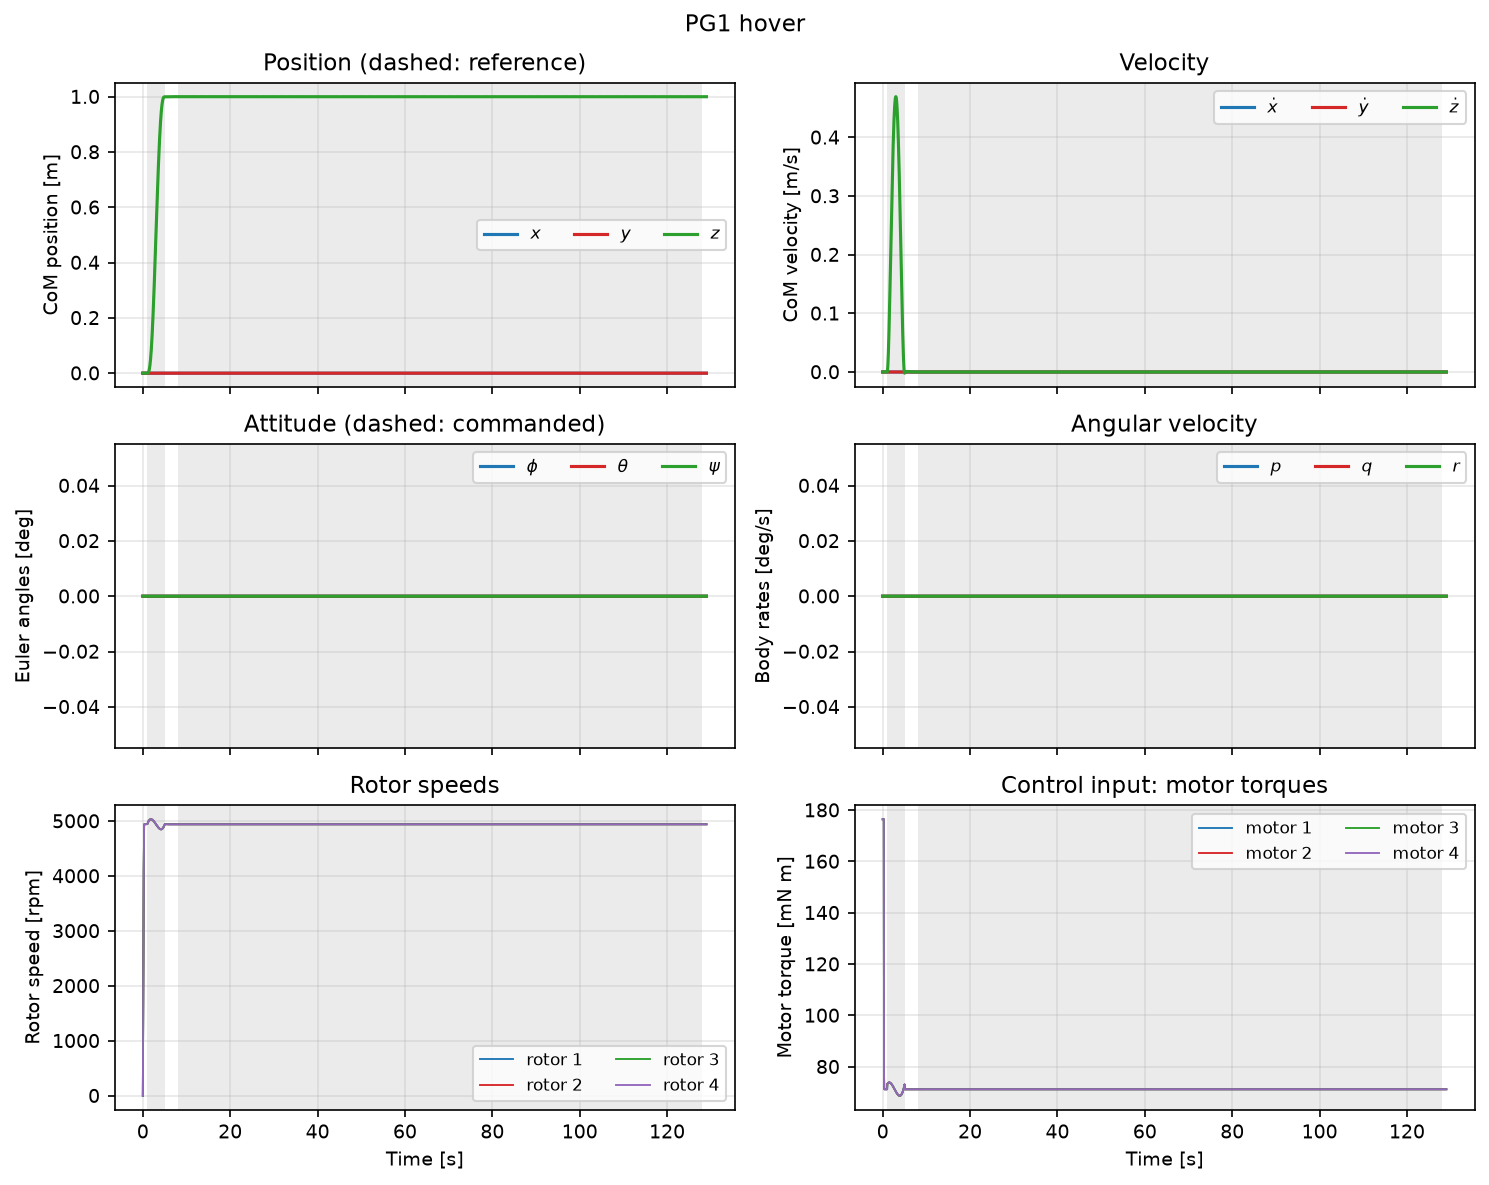

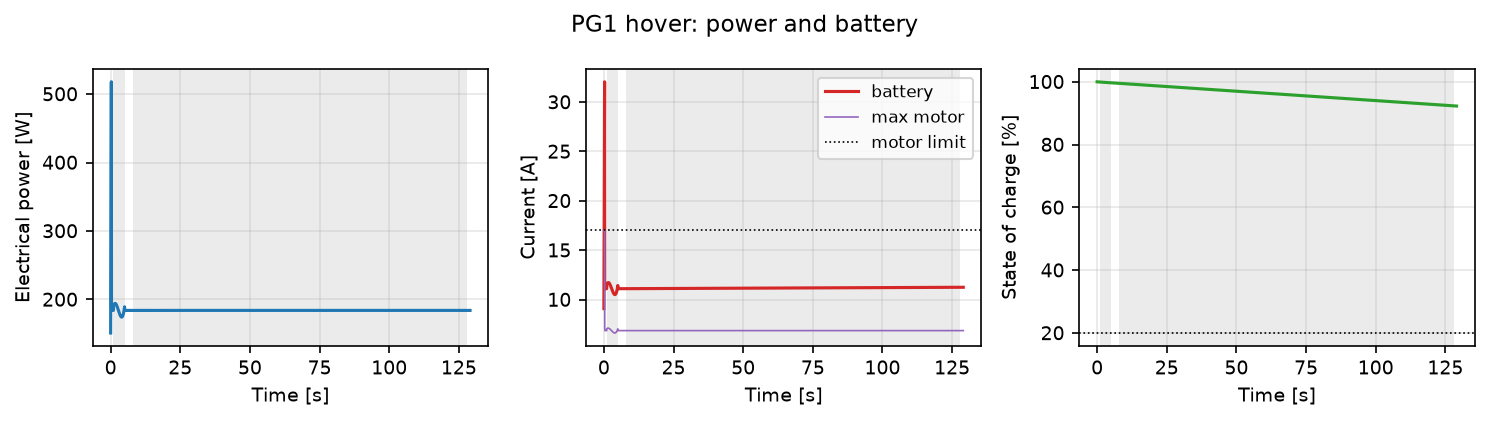

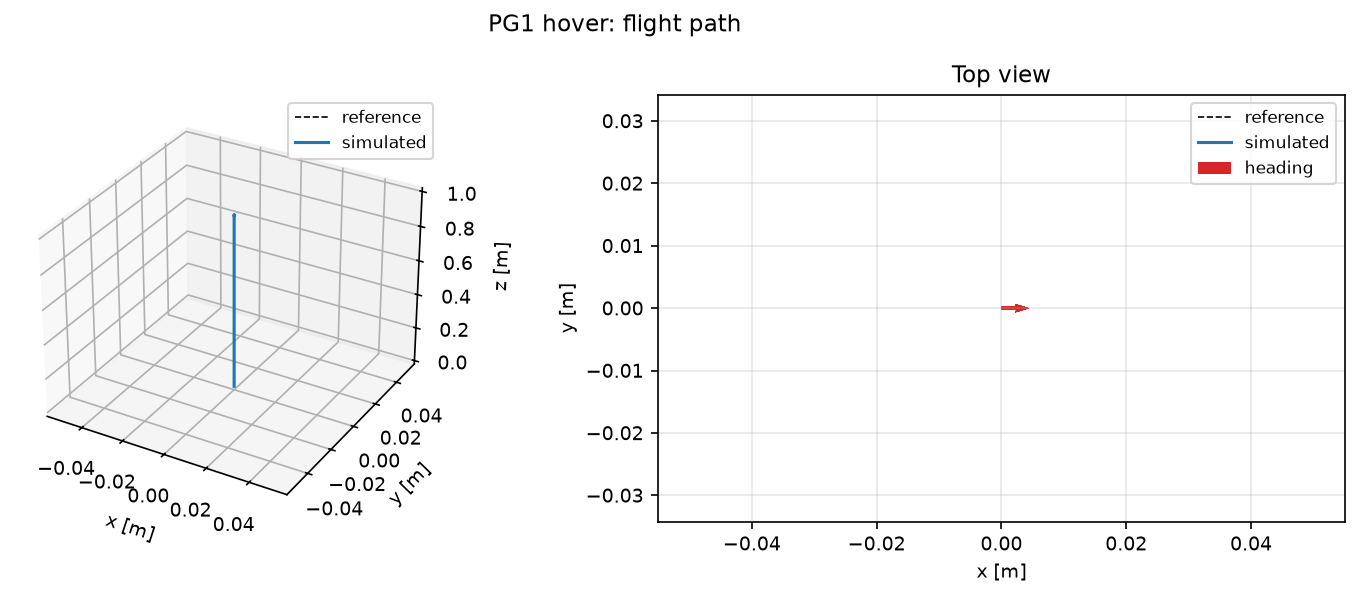

In [12]:
res_pg1 = run_mission("pg1")

### PG2: circle of radius 2 m at 1 m altitude, 0.5 m/s, at least 1 minute

=== PG2  PASS ===
  mass_kg                          1.552
  thrust_to_weight                 2.672
  hover_rpm                        4942
  max_rpm                          5034
  max_motor_current_A              17
  motor_current_limit_A            17
  max_battery_current_A            32.05
  energy_used_Wh                   5.268
  soc_end                          0.9386
  soc_reserve_ok                   True
  min_voltage_V                    16.16
  max_tilt_deg                     1.092
  circle_duration_s                71.4
  radius_mean_m                    2
  radius_max_dev_m                 0.002676
  speed_mean_mps                   0.5
  speed_min_mps                    0.4962
  speed_max_mps                    0.5037
  altitude_max_dev_m               5.199e-05


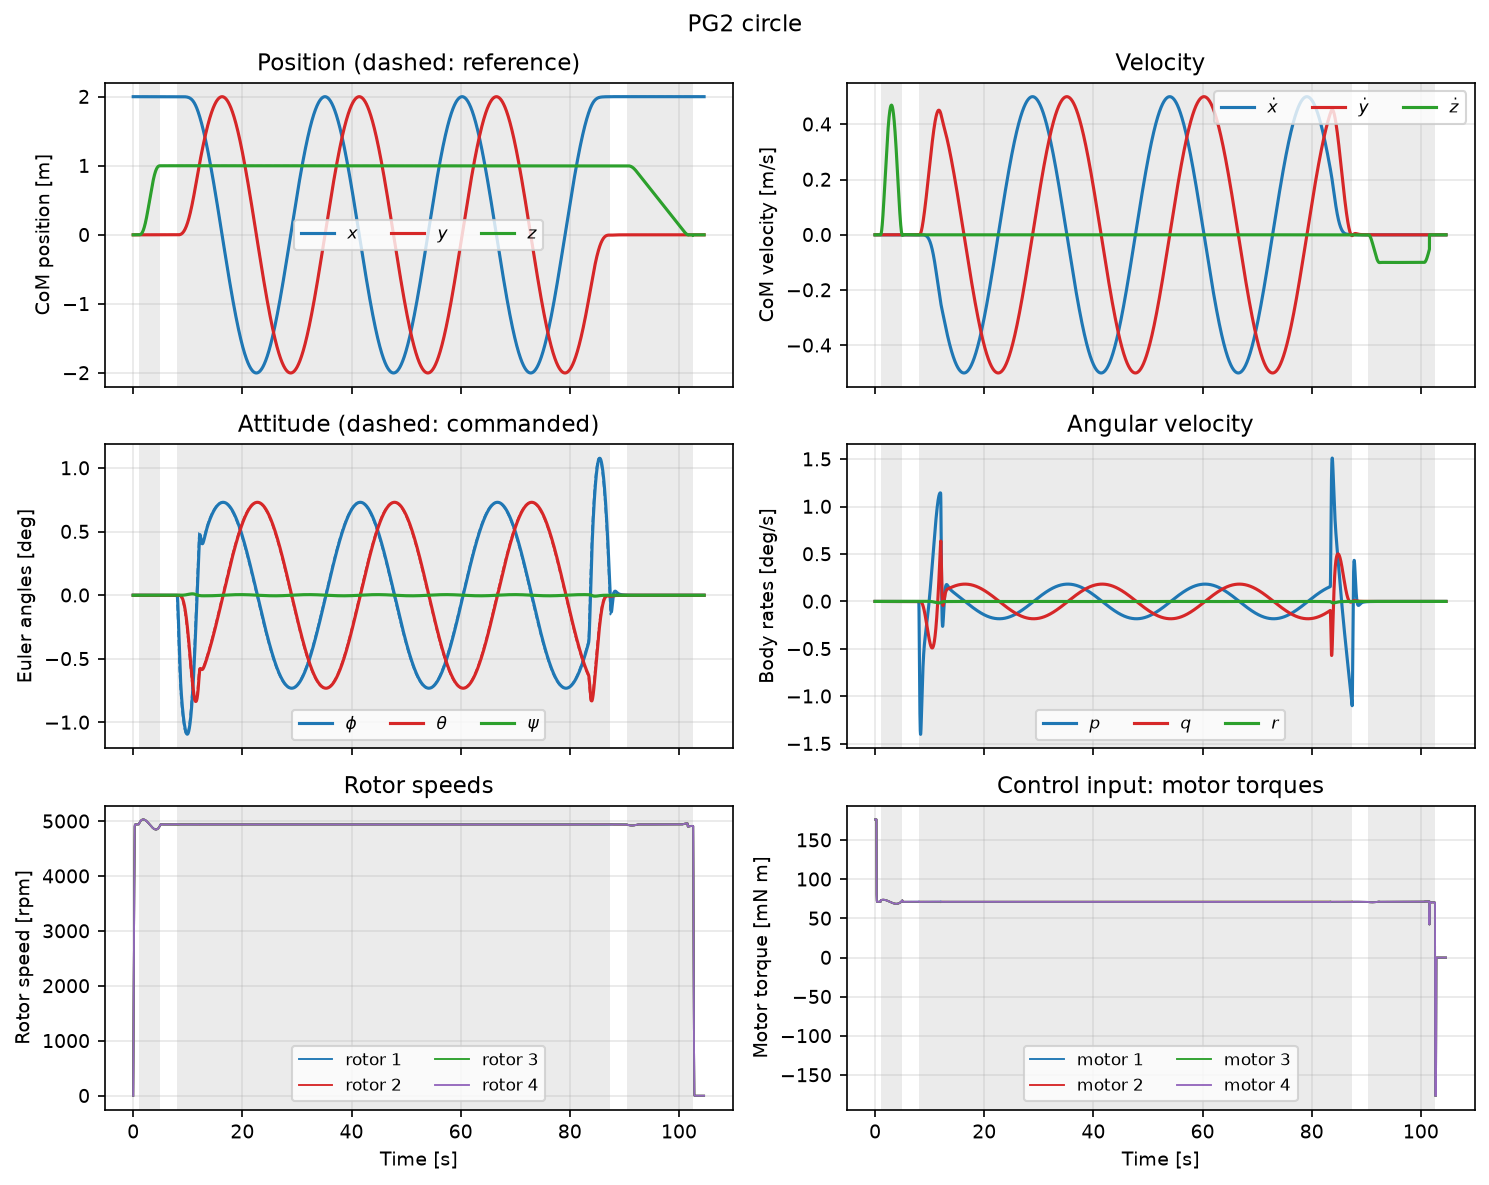

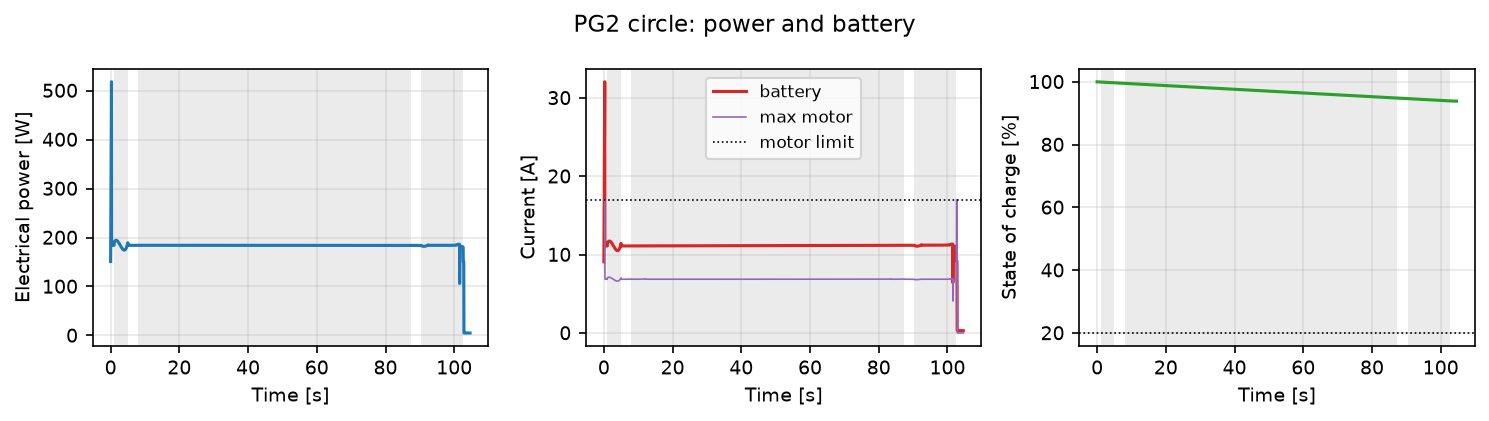

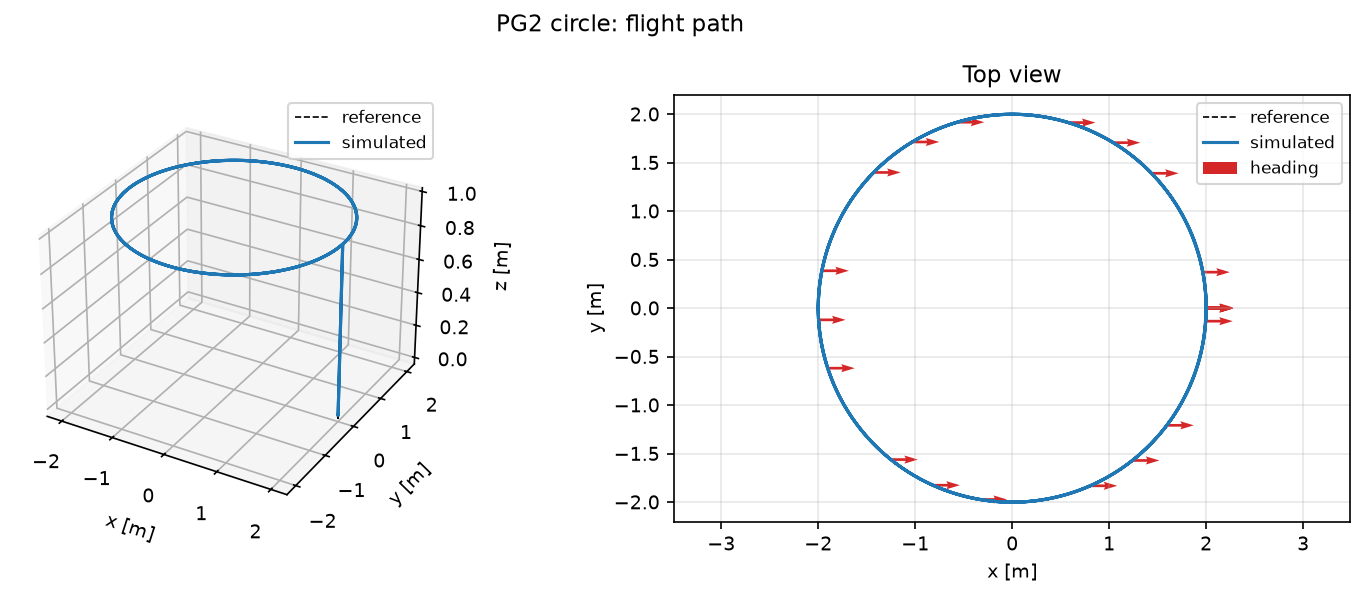

In [13]:
res_pg2 = run_mission("pg2")

### PG3: take off, 5 m legs at 1 m/s, yaw 90° left, land at ≤ 1 cm/s

=== PG3  PASS ===
  mass_kg                          1.552
  thrust_to_weight                 2.672
  hover_rpm                        4942
  max_rpm                          5109
  max_motor_current_A              17
  motor_current_limit_A            17
  max_battery_current_A            32.05
  energy_used_Wh                   8.178
  soc_end                          0.9043
  soc_reserve_ok                   True
  min_voltage_V                    16.16
  max_tilt_deg                     7.439
  leg1_distance_m                  5.003
  leg1_avg_speed_mps               1.001
  leg1_travel_time_1cm_s           5.766
  leg1_max_alt_dev_m               0.001326
  leg2_distance_m                  5.003
  leg2_avg_speed_mps               1.001
  leg2_travel_time_1cm_s           5.766
  leg2_max_alt_dev_m               0.001247
  yaw_change_deg                   90
  landing_max_descent_speed_mps    0.008051
  touchdown_time_s                 156
  touchdown_speed_mps              0.008
  

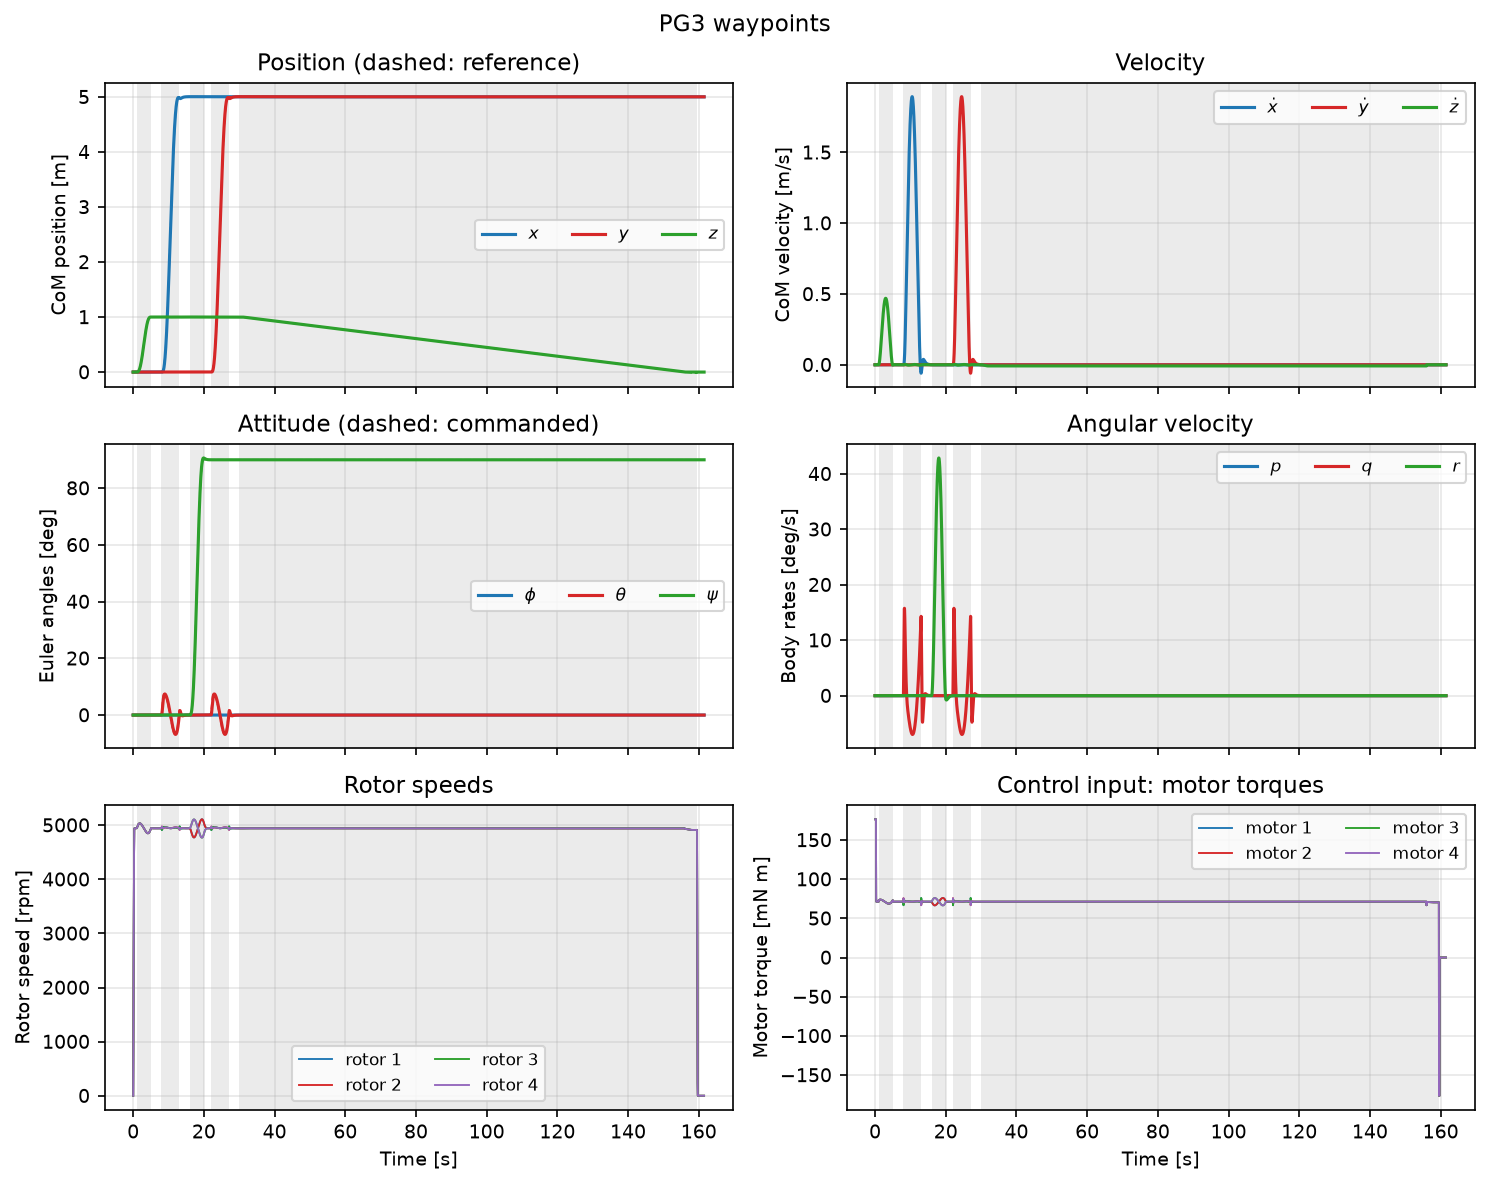

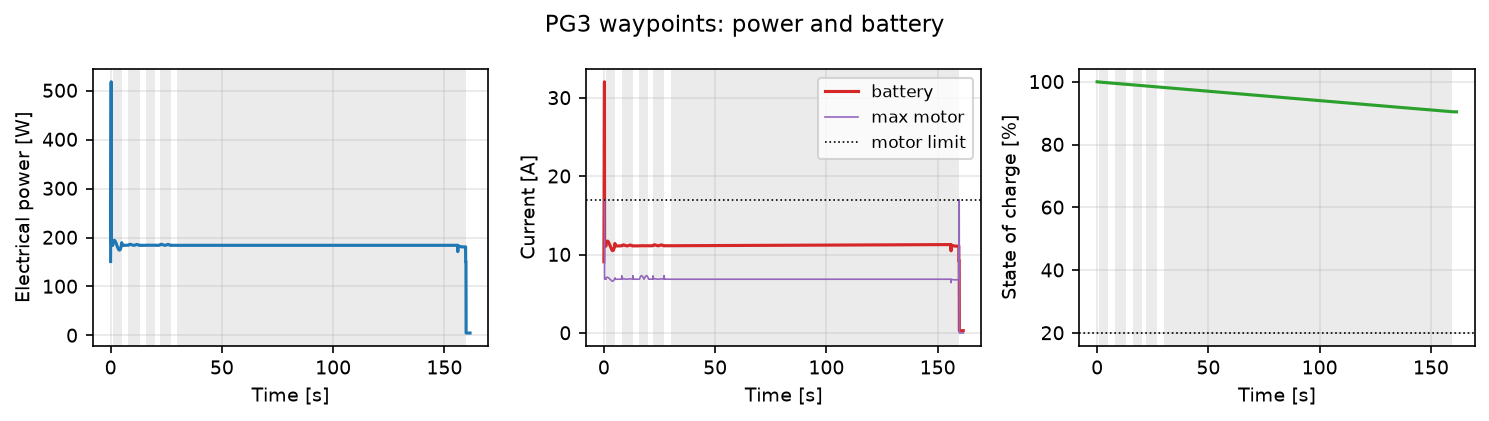

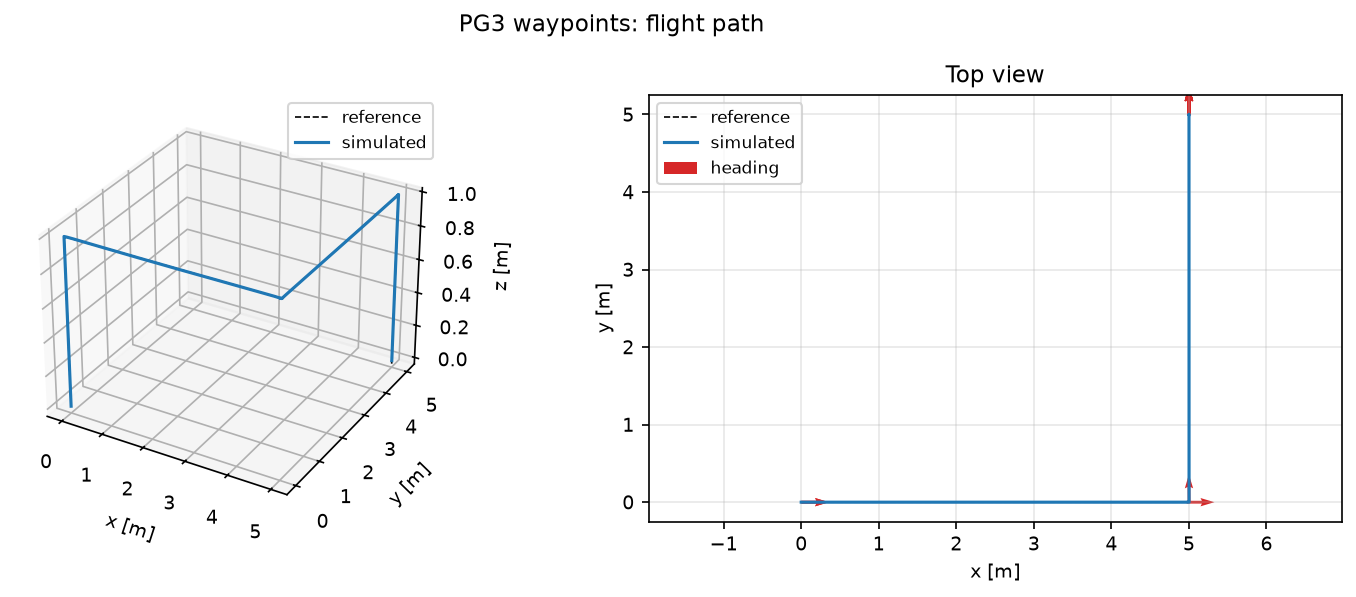

In [14]:
res_pg3 = run_mission("pg3")

### Summary

In [15]:
RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / "summary.json").write_text(json.dumps(results, indent=2))
for tag, m in results.items():
    print(f"{tag.upper()}: {'PASS' if m['pass'] else 'FAIL'}   battery left {100 * m['soc_end']:.1f} %")

PG1: PASS   battery left 92.3 %
PG2: PASS   battery left 93.9 %
PG3: PASS   battery left 90.4 %


## 10. Physics sanity tests

Checks of the equations of motion, controller and trajectories (about 5 s).

In [16]:
P = DroneParams()


def hover_state(z=1.0):
    return initial_state((0, 0, z), 0.0, P.omega_hover)


def hover_torque():
    return np.full(4, P.k_Q * P.omega_hover**2 + P.tau_friction * math.tanh(P.omega_hover / 5.0))


class TestParams(unittest.TestCase):
    def test_er4_mass_range(self):
        self.assertTrue(0.1 <= P.mass <= 10.0)

    def test_thrust_margin(self):
        self.assertGreater(4 * P.thrust_max / P.weight, 2.0)

    def test_hover_within_motor_limits(self):
        self.assertLess(hover_torque()[0], P.tau_motor_max)
        self.assertLess(P.omega_hover, P.omega_max())

    def test_inertia_symmetric_positive(self):
        np.testing.assert_allclose(P.I, P.I.T)
        self.assertTrue(np.all(np.linalg.eigvalsh(P.I) > 0))


class TestRotations(unittest.TestCase):
    def test_roundtrip(self):
        e = np.array([0.3, -0.2, 2.5])
        np.testing.assert_allclose(euler_from_matrix(rotation_matrix(*e)), e, atol=1e-12)

    def test_orthonormal(self):
        R = rotation_matrix(0.4, 0.1, -1.0)
        np.testing.assert_allclose(R @ R.T, np.eye(3), atol=1e-12)

    def test_euler_rates_level(self):
        np.testing.assert_allclose(euler_rate_matrix(0.0, 0.0), np.eye(3))


class TestEquationsOfMotion(unittest.TestCase):
    def test_hover_is_equilibrium(self):
        dx = derivatives(hover_state(), hover_torque(), P)
        np.testing.assert_allclose(dx[0:16], 0.0, atol=1e-9)

    def test_free_fall(self):
        x = hover_state()
        x[12:16] = 0.0
        dx = derivatives(x, np.zeros(4), P)
        self.assertAlmostEqual(dx[5], -P.g)

    def test_differential_thrust_rolls(self):
        """Extra lift on the left rotors (2, 3; y > 0) gives r x F = (y T, ...) > 0: positive roll rate
        (left side up, right side down) in FLU axes."""
        x = hover_state()
        x[12:16] = P.omega_hover * np.array([1.0, 1.05, 1.05, 1.0])
        dx = derivatives(x, hover_torque(), P)
        self.assertGreater(dx[9], 0.0)          # p_dot > 0
        self.assertAlmostEqual(dx[10], 0.0, places=9)

    def test_yaw_from_motor_torque_only(self):
        """ER2: increasing torque on CW motors (3, 4) yaws the body CCW (+r)."""
        tau = hover_torque() + np.array([0, 0, 0.01, 0.01])
        dx = derivatives(hover_state(), tau, P)
        self.assertGreater(dx[11], 0.0)

    def test_rotor_spinup_from_torque(self):
        tau = hover_torque() * 1.2
        dx = derivatives(hover_state(), tau, P)
        self.assertTrue(np.all(dx[12:16] > 0.0))

    def test_battery_drains(self):
        dx = derivatives(hover_state(), hover_torque(), P)
        self.assertGreater(dx[16], 0.0)

    def test_open_loop_hover_holds(self):
        x = hover_state()
        for _ in range(500):
            x = rk4_step(x, hover_torque(), 0.002, P)
        self.assertAlmostEqual(x[2], 1.0, places=2)


class TestController(unittest.TestCase):
    def test_mixer_inverts_allocation(self):
        c = Controller(P)
        u = np.array([P.weight, 0.01, -0.02, 0.003])
        np.testing.assert_allclose(c.A @ (c.A_inv @ u), u, atol=1e-12)

    def test_closed_loop_step(self):
        m = Mission("step", [Hold([0.5, -0.5, 1.5], 0.3, 15.0)])
        res = simulate(m, x0=hover_state())
        np.testing.assert_allclose(res.pos[-1], [0.5, -0.5, 1.5], atol=0.02)
        self.assertAlmostEqual(res.euler[-1, 2], 0.3, places=2)


class TestTrajectories(unittest.TestCase):
    def test_circle_closes(self):
        c = Circle([0, 0, 1], 2.0, 0.5, 3)
        np.testing.assert_allclose(c(0).pos, c(c.duration).pos, atol=1e-9)
        np.testing.assert_allclose(c(c.duration).vel, 0.0, atol=1e-9)

    def test_constant_speed_line(self):
        s = ConstantSpeedLine([0, 0, 1], [0, 0, 0], 0.008, 0.0)
        ts = np.linspace(0, s.duration, 2001)
        speeds = [np.linalg.norm(s(t).vel) for t in ts]
        self.assertLessEqual(max(speeds), 0.008 + 1e-12)
        np.testing.assert_allclose(s(s.duration).pos, [0, 0, 0], atol=1e-9)

In [17]:
suite = unittest.defaultTestLoader.loadTestsFromModule(__import__("__main__"))
unittest.TextTestRunner(verbosity=2).run(suite);

test_closed_loop_step (__main__.TestController.test_closed_loop_step) ... 

ok


test_mixer_inverts_allocation (__main__.TestController.test_mixer_inverts_allocation) ... 

ok


test_battery_drains (__main__.TestEquationsOfMotion.test_battery_drains) ... 

ok


... (27 outputs left out)

ok


test_constant_speed_line (__main__.TestTrajectories.test_constant_speed_line) ... 

ok


----------------------------------------------------------------------
Ran 18 tests in 4.732s

OK
